# Montage-derived assets for Case Study 2's R implementation

This notebook derives, from the real GSN-HydroCel-256 montage used by
`compute_psd.ipynb`, a handful of small, plain-CSV assets that let
**Case Study 2's R notebook** reproduce the same spatial structure
(channel adjacency, 2D topomap positions, scalp outline) **without**
needing an MNE/Python dependency inside R.

Nothing here is new data — it is a deterministic re-export of
`mne.channels.make_standard_montage("GSN-HydroCel-256")` and
`mne.channels.find_ch_adjacency()`, the same calls the Python notebook
makes directly. Re-run this notebook any time `channel_names.txt`
changes.

In [1]:
from pathlib import Path
import numpy as np
import mne
from mne.viz.topomap import _get_pos_outlines

mne.set_log_level("ERROR")

PSD_DIR = Path("../..") / "data" / "EEG" / "PSD" if Path.cwd().name != "PSD" else Path(".")
# running in place (data/EEG/PSD/), so just use the local directory
PSD_DIR = Path(".")

ch_names = [l.strip() for l in open(PSD_DIR / "channel_names.txt") if l.strip()]
n_ch = len(ch_names)
print(f"{n_ch} channels")

204 channels


## 1. Channel positions (3D) and spatial adjacency

In [2]:
montage = mne.channels.make_standard_montage("GSN-HydroCel-256")
ch_pos = montage.get_positions()["ch_pos"]

info = mne.create_info(ch_names, sfreq=1.0, ch_types="eeg")
info.set_montage(montage)

spatial_adjacency, ch_names_adj = mne.channels.find_ch_adjacency(info, ch_type="eeg")
assert list(ch_names_adj) == ch_names, "adjacency channel order must match channel_names.txt"
print(f"adjacency: {spatial_adjacency.shape}, {spatial_adjacency.nnz} edges (x2, symmetric)")

adjacency: (204, 204), 1380 edges (x2, symmetric)


In [3]:
import csv

with open(PSD_DIR / "montage_ch_pos_3d.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["channel", "x", "y", "z"])
    for ch in ch_names:
        x, y, z = ch_pos[ch]
        w.writerow([ch, x, y, z])
print("Saved: montage_ch_pos_3d.csv")

Saved: montage_ch_pos_3d.csv


In [4]:
coo = spatial_adjacency.tocoo()
with open(PSD_DIR / "montage_adjacency_edges.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["ch1", "ch2"])
    seen = set()
    for i, j in zip(coo.row, coo.col):
        if i == j:
            continue
        key = (min(i, j), max(i, j))
        if key in seen:
            continue
        seen.add(key)
        w.writerow([ch_names[key[0]], ch_names[key[1]]])
print(f"Saved: montage_adjacency_edges.csv ({len(seen)} undirected edges)")

Saved: montage_adjacency_edges.csv (588 undirected edges)


## 2. 2D topomap projection and scalp outline

These are the exact 2D positions and head/nose/ear outline curves
`mne.viz.plot_topomap` uses internally (via the private
`_get_pos_outlines` helper) for this montage — exporting them means the
R topomap function draws the same scalp cartoon without recomputing a
projection of its own.

In [5]:
picks = np.arange(n_ch)
pos2d, outlines = _get_pos_outlines(info, picks=picks, sphere=None)

with open(PSD_DIR / "montage_ch_pos_2d.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["channel", "x2d", "y2d"])
    for ch, (x2d, y2d) in zip(ch_names, pos2d):
        w.writerow([ch, x2d, y2d])
print("Saved: montage_ch_pos_2d.csv")

Saved: montage_ch_pos_2d.csv


In [6]:
parts = ["head", "nose", "ear_left", "ear_right"]
with open(PSD_DIR / "montage_outline.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["part", "x", "y"])
    for part in parts:
        xs, ys = outlines[part]
        for x, y in zip(xs, ys):
            w.writerow([part, x, y])
    # clip_radius is a scalar (circle radius); store as its own tiny row
    w.writerow(["clip_radius", outlines["clip_radius"][0], outlines["clip_radius"][1]])
print("Saved: montage_outline.csv")

Saved: montage_outline.csv


## 3. Sanity check

Quick re-plot from the exported CSVs alone (no live MNE calls) to
confirm nothing was lost in the round-trip.

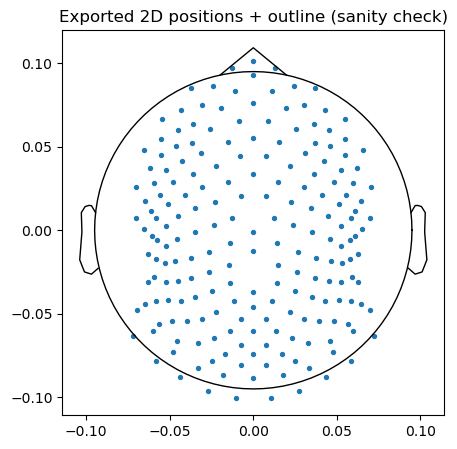

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
for part in parts:
    xs, ys = outlines[part]
    ax.plot(xs, ys, color="k", lw=1)
ax.scatter(pos2d[:, 0], pos2d[:, 1], s=8, color="C0")
ax.set_aspect("equal")
ax.set_title("Exported 2D positions + outline (sanity check)")
plt.show()